# 22 · Análisis exploratorio: el paquete de empates, los canaritos y la comparación final

**Etapa 28 del plan.** Tres pruebas en una corrida, todas en el banco temporal del `15` (201906 a 201910, 5 semillas, 296 árboles):

| Prueba | Qué compara | Para qué |
|---|---|---|
| **1. El paquete** | `PAQ_P3` − `ACH_4_P3` | **Decide.** Las combinaciones de Visa y Master con su historia (+0,58 M en el `17`) y los cambios relativos de Tomás (+0,64 M en el `20`) empataron a favor de a una. Juntas, en un solo modelo, pueden pasar el umbral |
| 2. El paquete con canaritos | `PAQ_C_P3` − `ACH_4_P3` | Informa. Las mismas columnas, sin las que el modelo usa menos que el ruido puro |
| 3. La comparación final | `ACH_4_P3` − `AC` y `ACH_4_P3` − `A-consigna` | Informa. Cuánto gana la estrategia vigente sobre el baseline, medido en una sola comparación |

| Configuración | Columnas | Peso de `BAJA+2` | Ventana |
|---|---:|---:|---|
| `ACH_4_P3` | 1.180 | 3 | Todos los meses hasta dos antes. Se lee del `15` |
| `PAQ_P3` | 1.180 + 215 (Visa y Master con historia) + 258 (`r1` y `r2`) = 1.653 | 3 | Igual |
| `PAQ_C_P3` | Las de `PAQ_P3` que superan a los canaritos, elegidas en cada mes | 3 | Igual |
| `AC` | 760: el baseline (lags y deltas de 1 y 2 meses) | 1 | Igual. Se lee del `15` |
| `A-consigna` | Las 760 de `AC` | 1 | 201903–06, la de la consigna. Solo se puede evaluar en 201908 a 201910 |

**Los canaritos** son columnas de números al azar. Se agregan, se entrena un modelo y se sacan las columnas reales que el modelo usa menos que el ruido. Es la receta de la cátedra (`1310_dataset_vidapropia.r`, función `CanaritosImportancia`).

**Todo lo de este notebook es exploratorio.** No cambia el resultado de la regla pre-registrada. No carga 201911 ni 201912. **No escribe en `exp/03/` a `exp/21/` ni en los `resultados/03_*` a `21_*`:** solo los lee.

Ficha: `fichas/etapa_28_canaritos.md` (en el laboratorio).

## 1. Parámetros

**Retomar:** si la corrida se corta, se vuelve a correr entera. Las selecciones y los modelos ya hechos no se repiten.

In [1]:
from pathlib import Path
import gc
import hashlib
import json
import resource
import sys
import time
import warnings

import duckdb
import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import FuncFormatter
from scipy import stats
from sklearn.metrics import roc_auc_score

# --- Parámetros -------------------------------------------------------------
BASE_PARQUET = Path('../data/base_2019.parquet')
RESULTADOS = Path('../resultados')
EXP_15 = Path('../exp/15')                          # solo se lee
EXP = Path('../exp/22')
FIGURAS = RESULTADOS / 'figuras'

MES_TOPE = 201910                                   # nada posterior entra a este notebook
MESES_TABLA = [201903, 201904, 201905, 201906, 201907, 201908, 201909, 201910]
MESES_EVALUADOS = [201906, 201907, 201908, 201909, 201910]
MESES_FINALES = [201909, 201910]
MESES_CONSIGNA = [201903, 201904, 201905, 201906]
ULTIMOS = 4
DISTANCIA = 2                                       # la clase de un mes se conoce dos meses después
MESES_TRAIN = MESES_CONSIGNA                        # los pide `construir`; acá cada modelo elige su ventana
MESES_EVAL = MESES_FINALES
ROTOS_EXTRA = [('ctarjeta_master_descuentos', 201910), ('mtarjeta_master_descuentos', 201910)]   # como en el 06 y el 12

CONTROL = 'AC'
BASE_CURADA = 'ACH'
JUNTAS = 'ACH_4'
NUEVAS = {'ACH': {'lags': [], 'tendencia': None, 'curada': True}}
CANDIDATAS = ['ACH_V', 'ACH_Q', 'ACH_T', 'ACH_Z']
REFERENCIA = 'ACH_4_P3'                             # la vigente del 15: sus predicciones se leen de exp/15
PESO_B2 = 3
PAQUETE = 'PAQ_P3'                                  # ACH_4 + Visa y Master con historia + cambios relativos
CON_CANARITOS = 'PAQ_C_P3'                          # el paquete, sin lo que queda debajo de los canaritos
CONSIGNA = 'A_CONSIGNA'                             # AC con la ventana de la consigna
CONFIGS = [PAQUETE, CON_CANARITOS]
DECIDE = PAQUETE
MESES_CONSIGNA_EVAL = [201908, 201909, 201910]      # con 201903-06 no se puede evaluar antes de 201908
CONTRASTES = [(PAQUETE, REFERENCIA, MESES_EVALUADOS), (CON_CANARITOS, REFERENCIA, MESES_EVALUADOS),
              (CON_CANARITOS, PAQUETE, MESES_EVALUADOS), (REFERENCIA, 'AC', MESES_EVALUADOS),
              (REFERENCIA, CONSIGNA, MESES_CONSIGNA_EVAL)]
HIPOTESIS = {PAQUETE: 'Los dos empates a favor juntos (Visa y Master con historia, y cambios relativos) ganan más que ACH_4_P3',
             CON_CANARITOS: 'El paquete sin las columnas que quedan debajo de los canaritos'}
LAGS_MV = [1, 2]                                    # como el 17
ROTO_NUEVO = ('Visa_mfinanciacion_limite', 201904)  # como el 17: solo en las combinaciones
LAGS_R = [1, 2]                                     # como el 20
CANARITOS_RATIO = 0.2                               # como la cátedra: tantos canaritos como el 20 % de las columnas
ENVIOS = [2_000, 3_000, 4_000, 5_000, 6_000, 8_000, 10_000]   # curva por cantidad de envíos, solo para informar
UMBRAL = 1.0                                        # M por mes, fijado en la ficha
FOTOS = 9                                           # 201910 llega hasta 201901

N_CURADAS = 30
MINIMO_PREVIOS = 2
BLOQUE = 20_000                                     # filas por bloque al armar las tablas

SEMILLA_PRIMIGENIA = 979201
N_SEMILLAS = 5
N_BOOTSTRAP = 2_000
BANDA = (3_000, 6_000)                              # ambos incluidos
EPSILON = 1e-12
POSITIVOS = ['BAJA+1', 'BAJA+2']
N_HILOS = 8

GANANCIA_ACIERTO = 1_072_500
COSTO_ESTIMULO = 27_500
LARGO_CURVA = 25_000
# -----------------------------------------------------------------------------

PRED = EXP / 'pred'
VARIABLES_CSV = RESULTADOS / '08_variables.csv'     # solo se lee
for d in (PRED, FIGURAS):
    d.mkdir(parents=True, exist_ok=True)
warnings.filterwarnings('ignore', message='.*ChainedAssignmentError.*')  # falso positivo pandas 2.2 + Py 3.14

ESPERADO_FILAS_POR_MES = {
    201901: 123_916, 201902: 125_020, 201903: 125_622, 201904: 126_116, 201905: 126_763,
    201906: 128_370, 201907: 129_853, 201908: 131_775, 201909: 133_419, 201910: 135_633,
}
ESPERADO_TABLA = (1_037_551, 5_042)                 # filas, BAJA+2
ESPERADO_N_VARIABLES = {'AC': 760, 'ACH': 880, 'ACH_4': 1_180, 'MV': 43, 'MVH': 215, 'R': 258}
N_MES = 152
ESPERADO_ROTOS = 23


def primos_6_digitos():
    criba = np.ones(1_000_000, dtype=bool)
    criba[:2] = False
    for i in range(2, 1_001):
        if criba[i]:
            criba[i * i::i] = False
    return np.flatnonzero(criba[100_000:]) + 100_000


TODAS = np.random.default_rng(SEMILLA_PRIMIGENIA).choice(primos_6_digitos(), size=20, replace=False).tolist()[:10]
assert TODAS == [294103, 342929, 161093, 677561, 431077, 330679, 511579, 312773, 118147, 567529]
SEMILLAS = TODAS[:N_SEMILLAS]


def huella_archivos():
    """Control 8: huella de las salidas anteriores, para comprobar que no cambian."""
    archivos = [*RESULTADOS.glob('0[3456789]_*'), *RESULTADOS.glob('1[0123456789]_*'), *RESULTADOS.glob('2[01]_*')]
    return {p.name: hashlib.blake2b(p.read_bytes(), digest_size=16).hexdigest() for p in sorted(archivos)}


def memoria_gb():
    r = resource.getrusage(resource.RUSAGE_SELF).ru_maxrss
    return round(r / (1e9 if sys.platform == 'darwin' else 1e6), 1)


HUELLA_INICIAL = huella_archivos()
T_INICIO = time.time()
print('Salidas anteriores registradas:', len(HUELLA_INICIAL))

Salidas anteriores registradas: 64


## 2. Dataset y funciones de evaluación

**Control 1:** filas y `BAJA+2` de 201903 a 201910. **Control 2:** nada posterior a 201910 entra al notebook. La clase de 201911 y 201912 nunca se carga.

In [2]:
def curva(prob, es_b2):
    orden = np.argsort(-prob, kind='stable')
    return np.cumsum(np.where(es_b2[orden], GANANCIA_ACIERTO, -COSTO_ESTIMULO))[:LARGO_CURVA].astype(np.float64)


def banda(cv):
    return cv[..., BANDA[0] - 1:BANDA[1]].mean(axis=-1)


HIPER = json.loads((RESULTADOS / '03_hiperparametros.json').read_text())

t0 = time.time()
con = duckdb.connect()
base = con.execute(f"""
    select * from read_parquet('{BASE_PARQUET.as_posix()}')
    where foto_mes <= {MES_TOPE}
    order by foto_mes, numero_de_cliente
""").df()
con.close()
assert base['foto_mes'].max() == MES_TOPE                                 # control 2
assert base['foto_mes'].value_counts().sort_index().to_dict() == ESPERADO_FILAS_POR_MES

CLAVES = ['numero_de_cliente', 'foto_mes', 'clase_ternaria']
VARIABLES = [c for c in base.columns if c not in CLAVES]
BANDERAS = ['active_quarter', 'cliente_vip', 'internet', 'cdescubierto_preacordado',
            'tcallcenter', 'thomebanking', 'tmobile_app', 'ccajas_transacciones']
ESTADOS = ['tcuentas', 'Visa_status', 'Master_status', 'Visa_delinquency', 'Master_delinquency']
FECHAS = [f'{t}_{c}' for t in ('Visa', 'Master') for c in ('Fvencimiento', 'Finiciomora', 'fultimo_cierre', 'fechaalta')]
EDADES = ['cliente_edad', 'cliente_antiguedad']
MONTOS = [v for v in VARIABLES if v not in BANDERAS + ESTADOS + FECHAS + EDADES]
assert len(VARIABLES) == 152 and len(MONTOS) == 129

rotos = pd.read_csv(RESULTADOS / '01_meses_rotos.csv')[['variable', 'foto_mes']]
assert len(rotos) == ESPERADO_ROTOS
rotos = pd.concat([rotos, pd.DataFrame(ROTOS_EXTRA, columns=['variable', 'foto_mes'])], ignore_index=True)
for v, mes in rotos.itertuples(index=False):
    base.loc[base['foto_mes'] == mes, v] = np.nan

FOTO_MES = base['foto_mes'].to_numpy()
PERIODO = (FOTO_MES // 100 * 12 + FOTO_MES % 100).astype(np.int64)
CLAVE = base['numero_de_cliente'].to_numpy(np.int64) * 100_000 + PERIODO
INDICE = pd.Index(CLAVE)
assert INDICE.is_unique
X_MES = np.asfortranarray(base[VARIABLES].to_numpy(np.float32))
CLASE = base['clase_ternaria'].to_numpy()
del base
gc.collect()
print(f'Dataset cargado en {time.time() - t0:.0f} s')

Dataset cargado en 1 s


## 3. Tablas de `ACH_4`

Las mismas columnas de `ACH_4` del `15`: 1.180, el baseline más la historia curada y los cuatro bloques del `14`.

**Control 4:** una columna da lo mismo calculada solo con datos hasta su mes. **Control 6:** fórmulas a mano en 300 clientes.

In [3]:
SIN_HISTORIA = {'lags': [], 'tendencia': None, 'curada': False}


def receta(config):
    return SIN_HISTORIA if config == CONTROL else NUEVAS[config]


def especificacion(config):
    ex = receta(config)
    e = [('original', v, 0) for v in VARIABLES]
    e += [(op, v, k) for k in (1, 2) for op in ('lag', 'delta') for v in VARIABLES]
    for k in ex['lags']:
        e += [(op, v, k) for op in ('lag', 'delta') for v in MONTOS + BANDERAS]
        e += [(op, v, k) for op in ('lag', 'cambio') for v in ESTADOS]
    if ex['tendencia']:
        h = ex['tendencia']
        e += [(op, v, h) for op in ('pend', 'prom', 'min', 'max') for v in MONTOS]
        e += [('perm', v, h) for v in BANDERAS]
    if ex['curada']:
        assert len(CURADAS) == N_CURADAS
        e += [(op, v, k) for op, k in (('ratio', 3), ('z', 4), ('relmax', 4), ('mes_ratio', 3)) for v in CURADAS]
    return e


def nombre(op, v, k):
    return v if op == 'original' else f'{v}_{op}{k}'


def construir(config, meses=None):
    ex = receta(config)
    h = ex['tendencia']
    h_max = max([2] + ex['lags'] + [h or 0] + ([4] if ex['curada'] else []))
    filas = np.flatnonzero(np.isin(FOTO_MES, meses or MESES_TRAIN + MESES_EVAL))
    mes_fila = FOTO_MES[filas]
    n_train = int(np.isin(mes_fila, MESES_TRAIN).sum())
    assert meses or (np.isin(mes_fila[:n_train], MESES_TRAIN).all() and np.isin(mes_fila[n_train:], MESES_EVAL).all())
    pos = {k: INDICE.get_indexer(CLAVE[filas] - k) for k in range(h_max + 1)}

    espec = especificacion(config)
    ubic = {e: i for i, e in enumerate(espec)}
    F = np.empty((len(filas), len(espec)), dtype=np.float32)
    t = -np.arange((h or 0) + 1, dtype=np.float64)[:, None]
    # Por bloques de filas: escribir columna por columna recorre toda la tabla en cada pasada,
    # y con una tabla de más de ~4,5 GB eso tardó decenas de minutos.
    with np.errstate(invalid='ignore', divide='ignore'):
        for inicio in range(0, len(filas), BLOQUE):
            fb = slice(inicio, inicio + BLOQUE)
            for j, v in enumerate(VARIABLES):
                F[fb, ubic[('original', v, 0)]] = X_MES[filas[fb], j]
                hk = {}
                for k in range(h_max + 1):
                    col = X_MES[pos[k][fb], j]
                    col[pos[k][fb] < 0] = np.nan
                    hk[k] = col
                for k in range(1, h_max + 1):
                    if ('lag', v, k) in ubic:
                        F[fb, ubic[('lag', v, k)]] = hk[k]
                    if ('delta', v, k) in ubic:
                        F[fb, ubic[('delta', v, k)]] = hk[0] - hk[k]
                    if ('cambio', v, k) in ubic:
                        a, b = hk[0], hk[k]
                        F[fb, ubic[('cambio', v, k)]] = np.where(np.isnan(a) | np.isnan(b), np.nan, (a != b).astype(np.float32))
                if h and (('prom', v, h) in ubic or ('perm', v, h) in ubic):
                    S = np.stack([hk[k] for k in range(h + 1)]).astype(np.float64)
                    valido = ~np.isnan(S)
                    cuantos = valido.sum(axis=0)
                    S0 = np.where(valido, S, 0.0)
                    if ('perm', v, h) in ubic:
                        F[fb, ubic[('perm', v, h)]] = np.where(cuantos > 0, S0.sum(axis=0), np.nan)
                    else:
                        prom = S0.sum(axis=0) / cuantos
                        dt = np.where(valido, t - (valido * t).sum(axis=0) / cuantos, 0.0)
                        pend = (dt * (S0 - prom)).sum(axis=0) / (dt ** 2).sum(axis=0)
                        pend[cuantos < 2] = np.nan
                        F[fb, ubic[('pend', v, h)]] = pend
                        F[fb, ubic[('prom', v, h)]] = prom
                        F[fb, ubic[('min', v, h)]] = np.where(cuantos > 0, np.where(valido, S, np.inf).min(axis=0), np.nan)
                        F[fb, ubic[('max', v, h)]] = np.where(cuantos > 0, np.where(valido, S, -np.inf).max(axis=0), np.nan)
                if ('ratio', v, 3) in ubic:
                    a, b, c = (hk[k].astype(np.float64) for k in range(3))
                    media3 = (a + b + c) / 3                  # NA si falta alguna foto
                    ratio = np.where(np.abs(media3) > EPSILON, a / media3, np.nan)
                    F[fb, ubic[('ratio', v, 3)]] = ratio
                    x = a
                    P = np.stack([hk[k] for k in range(1, 5)]).astype(np.float64)
                    valido = ~np.isnan(P)
                    cuantos = valido.sum(axis=0)
                    alcanza = (cuantos >= MINIMO_PREVIOS) & ~np.isnan(x)
                    media = np.where(valido, P, 0.0).sum(axis=0) / cuantos
                    desvio = np.sqrt(np.where(valido, (P - media) ** 2, 0.0).sum(axis=0) / cuantos)
                    maximo = np.where(valido, P, -np.inf).max(axis=0)
                    F[fb, ubic[('z', v, 4)]] = np.where(alcanza & (desvio > EPSILON), (x - media) / desvio, np.nan)
                    F[fb, ubic[('relmax', v, 4)]] = np.where(alcanza & (maximo > EPSILON), x / maximo, np.nan)
    for v in (CURADAS if ex['curada'] else []):           # el percentil necesita el mes entero
        F[:, ubic[('mes_ratio', v, 3)]] = pd.Series(F[:, ubic[('ratio', v, 3)]]).groupby(mes_fila).rank(pct=True).to_numpy(np.float32)
    return {'F': F, 'columnas': [nombre(*e) for e in espec], 'espec': espec, 'filas': filas, 'mes_fila': mes_fila,
            'n_train': n_train, 'lags': sorted({k for op, _, k in espec if op == 'lag'}), 'h': h}


CURADAS = pd.read_csv(VARIABLES_CSV)['variable'].tolist()
assert len(CURADAS) == N_CURADAS and set(CURADAS) <= set(MONTOS)


def cero_fijo(x, mes):
    """Percentil dentro del mes: positivos de 0 a 1, negativos de 0 a -1, y el cero en 0."""
    s = pd.Series(x)
    arriba = s.where(s > 0).groupby(mes).rank(pct=True).fillna(0)
    abajo = (-s).where(s < 0).groupby(mes).rank(pct=True).fillna(0)
    return (arriba - abajo).where(s.notna()).to_numpy()


def bloques_nuevos(filas, X, indice, clave, foto_mes):
    """Cada fila usa solo fotos de su mes o anteriores. El percentil usa solo su mes."""
    pos = [indice.get_indexer(clave[filas] - k) for k in range(FOTOS + 1)]
    mes = foto_mes[filas]
    salida = {b: {} for b in CANDIDATAS}
    with np.errstate(invalid='ignore', divide='ignore'):
        for v in CURADAS:
            j = VARIABLES.index(v)
            H = np.stack([np.where(p >= 0, X[p, j], np.nan) for p in pos]).astype(np.float64)
            a, b, c, d = H[:4]
            dif = np.stack([a - b, b - c, c - d])
            valido = ~np.isnan(dif)
            cuantos = valido.sum(axis=0)
            alcanza = cuantos >= MINIMO_PREVIOS
            media = np.where(valido, dif, 0.0).sum(axis=0) / cuantos
            desvio = np.sqrt(np.where(valido, (dif - media) ** 2, 0.0).sum(axis=0) / cuantos)
            salida['ACH_V'][f'{v}_std3'] = np.stack([a, b, c]).std(axis=0)
            salida['ACH_V'][f'{v}_dstd3'] = np.where(alcanza, desvio, np.nan)
            salida['ACH_Q'][f'{v}_q4'] = (a + b) / 2 - (c + d) / 2
            salida['ACH_Q'][f'{v}_peor3'] = np.where(alcanza, np.where(valido, dif, np.inf).min(axis=0), np.nan)
            salida['ACH_Q'][f'{v}_caidas3'] = np.where(alcanza, (dif < 0).sum(axis=0), np.nan)
            P = H[1:]
            valido = ~np.isnan(P)
            cuantos = valido.sum(axis=0)
            alcanza = (cuantos >= MINIMO_PREVIOS) & ~np.isnan(a)
            maximo = np.where(valido, P, -np.inf).max(axis=0)
            media = np.where(valido, P, 0.0).sum(axis=0) / cuantos
            salida['ACH_T'][f'{v}_relmaxT'] = np.where(alcanza & (maximo > EPSILON), a / maximo, np.nan)
            salida['ACH_T'][f'{v}_relmediaT'] = np.where(alcanza & (np.abs(media) > EPSILON), a / media, np.nan)
            salida['ACH_T'][f'{v}_desdemaxT'] = np.where(alcanza, np.where(np.isnan(H), -np.inf, H).argmax(axis=0), np.nan)
            salida['ACH_Z'][f'{v}_zc1'] = cero_fijo(a - b, mes)
            salida['ACH_Z'][f'{v}_zc2'] = cero_fijo(a - c, mes)
    return {b: (np.column_stack(list(c.values())).astype(np.float32), list(c)) for b, c in salida.items()}


t0 = time.time()
T = construir(BASE_CURADA, meses=MESES_TABLA)
assert T['F'].shape == (ESPERADO_TABLA[0], ESPERADO_N_VARIABLES[BASE_CURADA]), T['F'].shape
assert T['columnas'][:N_MES] == VARIABLES and T['columnas'][ESPERADO_N_VARIABLES[CONTROL]].endswith('_ratio3')
assert (CLASE[T['filas']] == 'BAJA+2').sum() == ESPERADO_TABLA[1]         # control 1
B = bloques_nuevos(T['filas'], X_MES, INDICE, CLAVE, FOTO_MES)
assert {b: v[0].shape[1] for b, v in B.items()} == {'ACH_V': 60, 'ACH_Q': 90, 'ACH_T': 90, 'ACH_Z': 60}

CLIENTE_FILA = CLAVE[T['filas']] // 100_000
CLIENTES, POS_CLIENTE = np.unique(CLIENTE_FILA, return_inverse=True)

# Control 4: sin fuga. Con los datos cortados en el mes, cada columna tiene que dar lo mismo.
for corte in (201905, 201906, 201909):
    hasta = FOTO_MES <= corte
    filas_c = np.flatnonzero(FOTO_MES[hasta] == corte)
    C = bloques_nuevos(filas_c, X_MES[hasta], pd.Index(CLAVE[hasta]), CLAVE[hasta], FOTO_MES[hasta])
    en_mes = T['mes_fila'] == corte
    for b in CANDIDATAS:
        assert np.array_equal(C[b][0], B[b][0][en_mes], equal_nan=True), (b, corte)
    del C

# Control 6: fórmulas a mano
rng = np.random.default_rng(SEMILLA_PRIMIGENIA)
muestra = rng.choice(len(T['filas']), size=300, replace=False)
col = {b: {c: i for i, c in enumerate(B[b][1])} for b in CANDIDATAS}


def igual(bloque, nombre_columna, fila, esperado):
    valor = B[bloque][0][fila, col[bloque][nombre_columna]]
    if esperado is None:
        assert np.isnan(valor), (nombre_columna, fila, valor)
    else:
        np.testing.assert_allclose(valor, esperado, rtol=1e-3, atol=1e-3, err_msg=nombre_columna)


for v in CURADAS[:3]:
    serie = pd.Series(X_MES[:, VARIABLES.index(v)].astype(np.float64), index=INDICE)
    for i in muestra:
        clave = CLAVE[T['filas'][i]]
        y = [serie.get(clave - k, np.nan) for k in range(FOTOS + 1)]
        igual('ACH_V', f'{v}_std3', i, None if np.isnan(y[:3]).any() else float(np.std(y[:3])))
        igual('ACH_Q', f'{v}_q4', i, None if np.isnan(y[:4]).any() else (y[0] + y[1]) / 2 - (y[2] + y[3]) / 2)
        dif = [y[k] - y[k + 1] for k in range(3)]
        hay = [x for x in dif if not np.isnan(x)]
        igual('ACH_V', f'{v}_dstd3', i, float(np.std(hay)) if len(hay) >= 2 else None)
        igual('ACH_Q', f'{v}_peor3', i, min(hay) if len(hay) >= 2 else None)
        igual('ACH_Q', f'{v}_caidas3', i, sum(x < 0 for x in hay) if len(hay) >= 2 else None)
        previos = [x for x in y[1:] if not np.isnan(x)]
        alcanza = len(previos) >= 2 and not np.isnan(y[0])
        igual('ACH_T', f'{v}_relmaxT', i, y[0] / max(previos) if alcanza and max(previos) > EPSILON else None)
        igual('ACH_T', f'{v}_relmediaT', i, y[0] / np.mean(previos) if alcanza and abs(np.mean(previos)) > EPSILON else None)
        igual('ACH_T', f'{v}_desdemaxT', i, int(np.nanargmax(y)) if alcanza else None)
v = CURADAS[0]
en_mes = T['mes_fila'] == 201906
d = T['F'][en_mes, T['columnas'].index(f'{v}_delta1')].astype(np.float64)
z = B['ACH_Z'][0][en_mes, col['ACH_Z'][f'{v}_zc1']]
assert (np.isnan(d) == np.isnan(z)).all() and (np.sign(d[~np.isnan(d)]) == np.sign(z[~np.isnan(z)])).all()
hay = d > 0
np.testing.assert_allclose(z[hay], stats.rankdata(d[hay]) / hay.sum(), rtol=1e-5)
print(f'Tablas y controles 4 y 6 OK en {time.time() - t0:.0f} s · memoria máxima {memoria_gb()} GB')

Tablas y controles 4 y 6 OK en 23 s · memoria máxima 5.8 GB


## 4. Combinaciones de Visa y Master, con su historia

El mismo código del `17`: las 43 combinaciones de `951_dataset_epic.r` y su lag y delta de 1 y 2 meses (215 columnas). Si una de las dos tarjetas tiene roto el mes, la combinación queda vacía; además se trata como roto `Visa_mfinanciacion_limite` de 201904, solo en las combinaciones.

**Control 4:** cada columna da lo mismo calculada solo con datos hasta su mes. **Control 6:** fórmulas a mano en 300 clientes, y los meses rotos vacíos.

In [4]:
SUMAS = ['mfinanciacion_limite', 'msaldototal', 'msaldopesos', 'msaldodolares', 'mconsumospesos', 'mconsumosdolares',
         'mlimitecompra', 'madelantopesos', 'madelantodolares', 'mpagado', 'mpagospesos', 'mpagosdolares',
         'mconsumototal', 'cconsumos', 'cadelantosefectivo', 'mpagominimo']
MINIMOS = ['Fvencimiento', 'Finiciomora']
MAXIMOS = ['fultimo_cierre', 'fechaalta']
COCIENTES = [('mvr_Master_mlimitecompra', 'Master_mlimitecompra', 'mv_mlimitecompra'),
             ('mvr_Visa_mlimitecompra', 'Visa_mlimitecompra', 'mv_mlimitecompra'),
             ('mvr_msaldototal', 'mv_msaldototal', 'mv_mlimitecompra'),
             ('mvr_msaldopesos', 'mv_msaldopesos', 'mv_mlimitecompra'),
             ('mvr_msaldopesos2', 'mv_msaldopesos', 'mv_msaldototal'),
             ('mvr_msaldodolares', 'mv_msaldodolares', 'mv_mlimitecompra'),
             ('mvr_msaldodolares2', 'mv_msaldodolares', 'mv_msaldototal'),
             ('mvr_mconsumospesos', 'mv_mconsumospesos', 'mv_mlimitecompra'),
             ('mvr_mconsumosdolares', 'mv_mconsumosdolares', 'mv_mlimitecompra'),
             ('mvr_madelantopesos', 'mv_madelantopesos', 'mv_mlimitecompra'),
             ('mvr_madelantodolares', 'mv_madelantodolares', 'mv_mlimitecompra'),
             ('mvr_mpagado', 'mv_mpagado', 'mv_mlimitecompra'),
             ('mvr_mpagospesos', 'mv_mpagospesos', 'mv_mlimitecompra'),
             ('mvr_mpagosdolares', 'mv_mpagosdolares', 'mv_mlimitecompra'),
             ('mvr_mconsumototal', 'mv_mconsumototal', 'mv_mlimitecompra'),
             ('mvr_mpagominimo', 'mv_mpagominimo', 'mv_mlimitecompra')]
ROTOS_MV = {(v, int(m)) for v, m in rotos.itertuples(index=False)} | {ROTO_NUEVO}
assert all(f'{t}_{c}' in VARIABLES for t in ('Master', 'Visa') for c in SUMAS + MINIMOS + MAXIMOS)


def combinaciones(X, foto_mes):
    """Las 43 combinaciones del mes, fila por fila. Solo usan la foto de esa fila."""
    col = lambda v: X[:, VARIABLES.index(v)].astype(np.float64)
    roto = lambda v: np.isin(foto_mes, [m for w, m in ROTOS_MV if w == v])
    s = {}
    ms, vs = col('Master_status'), col('Visa_status')
    m10, v10 = np.where(np.isnan(ms), 10, ms), np.where(np.isnan(vs), 10, vs)
    s['mv_status01'] = np.fmax(ms, vs)
    s['mv_status02'] = ms + vs
    s['mv_status03'] = np.maximum(m10, v10)
    s['mv_status04'] = m10 + v10
    s['mv_status05'] = m10 + 100 * v10
    s['mv_status06'] = np.where(np.isnan(vs), m10, vs)
    s['mv_status07'] = np.where(np.isnan(ms), v10, ms)
    for c in SUMAS:
        s[f'mv_{c}'] = np.nan_to_num(col(f'Master_{c}')) + np.nan_to_num(col(f'Visa_{c}'))
    for c in MINIMOS:
        s[f'mv_{c}'] = np.fmin(col(f'Master_{c}'), col(f'Visa_{c}'))
    for c in MAXIMOS:
        s[f'mv_{c}'] = np.fmax(col(f'Master_{c}'), col(f'Visa_{c}'))
    for c in SUMAS + MINIMOS + MAXIMOS:
        s[f'mv_{c}'][roto(f'Master_{c}') | roto(f'Visa_{c}')] = np.nan
    with np.errstate(invalid='ignore', divide='ignore'):
        for nombre_c, num, den in COCIENTES:
            n = s[num] if num in s else col(num)
            s[nombre_c] = np.where(np.abs(s[den]) > EPSILON, n / s[den], np.nan)
    return np.column_stack(list(s.values())).astype(np.float32), list(s)


def bloque_mv(filas, X, indice, clave, foto_mes):
    """MV: las 43 del mes. MVH: además, lag y delta de 1 y 2 meses. Cada fila usa solo fotos de su mes o anteriores."""
    C, nombres = combinaciones(X, foto_mes)
    H = {}
    for k in [0] + LAGS_MV:
        p = indice.get_indexer(clave[filas] - k)
        H[k] = np.where((p >= 0)[:, None], C[np.maximum(p, 0)], np.float32(np.nan))
    partes, columnas = [H[0]], list(nombres)
    for k in LAGS_MV:
        partes += [H[k], H[0] - H[k]]
        columnas += [f'{n}_lag{k}' for n in nombres] + [f'{n}_delta{k}' for n in nombres]
    MVH = np.hstack(partes).astype(np.float32)
    return {'MV': (MVH[:, :len(nombres)], list(nombres)), 'MVH': (MVH, columnas)}


t0 = time.time()
BMV = bloque_mv(T['filas'], X_MES, INDICE, CLAVE, FOTO_MES)
assert {b: v[0].shape for b, v in BMV.items()} == {b: (ESPERADO_TABLA[0], ESPERADO_N_VARIABLES[b]) for b in BMV}
assert not set(BMV['MVH'][1]) & set(T['columnas'] + [c for b in CANDIDATAS for c in B[b][1]])

# Control 4: sin fuga
for corte in (201905, 201906, 201909):
    hasta = FOTO_MES <= corte
    filas_c = np.flatnonzero(FOTO_MES[hasta] == corte)
    C = bloque_mv(filas_c, X_MES[hasta], pd.Index(CLAVE[hasta]), CLAVE[hasta], FOTO_MES[hasta])['MVH'][0]
    assert np.array_equal(C, BMV['MVH'][0][T['mes_fila'] == corte], equal_nan=True), corte
    del C

# Control 6: fórmulas a mano, con pandas, fila por fila
col_mv = {c: i for i, c in enumerate(BMV['MVH'][1])}
serie = {v: pd.Series(X_MES[:, VARIABLES.index(v)].astype(np.float64), index=INDICE)
         for v in ['Master_msaldototal', 'Visa_msaldototal', 'Master_mlimitecompra', 'Visa_mlimitecompra',
                   'Master_Finiciomora', 'Visa_Finiciomora', 'Master_status', 'Visa_status']}


def a_mano(clave):
    """Valores esperados para una clave cliente-período; NA si la foto no existe."""
    if clave not in INDICE:
        return None
    g = {v: serie[v][clave] for v in serie}
    suma = lambda c: (0 if np.isnan(g[f'Master_{c}']) else g[f'Master_{c}']) + (0 if np.isnan(g[f'Visa_{c}']) else g[f'Visa_{c}'])
    saldo, limite = suma('msaldototal'), suma('mlimitecompra')
    fechas = [x for x in (g['Master_Finiciomora'], g['Visa_Finiciomora']) if not np.isnan(x)]
    m10 = 10 if np.isnan(g['Master_status']) else g['Master_status']
    v10 = 10 if np.isnan(g['Visa_status']) else g['Visa_status']
    return {'mv_msaldototal': saldo, 'mv_mlimitecompra': limite,
            'mvr_msaldototal': saldo / limite if abs(limite) > EPSILON else np.nan,
            'mv_Finiciomora': min(fechas) if fechas else np.nan, 'mv_status05': m10 + 100 * v10}


rng = np.random.default_rng(SEMILLA_PRIMIGENIA + 17)
for i in rng.choice(len(T['filas']), size=300, replace=False):
    clave = CLAVE[T['filas'][i]]
    hoy = a_mano(clave)
    for c, x in hoy.items():
        np.testing.assert_allclose(BMV['MVH'][0][i, col_mv[c]], x, rtol=1e-4, atol=1e-3, err_msg=c)
    for k in LAGS_MV:
        antes = a_mano(clave - k)
        for c in ('mvr_msaldototal', 'mv_msaldototal'):
            lag = np.nan if antes is None else antes[c]
            np.testing.assert_allclose(BMV['MVH'][0][i, col_mv[f'{c}_lag{k}']], lag, rtol=1e-4, atol=1e-3, err_msg=f'{c}_lag{k}')
            np.testing.assert_allclose(BMV['MVH'][0][i, col_mv[f'{c}_delta{k}']], hoy[c] - lag, rtol=1e-4, atol=1e-1, err_msg=f'{c}_delta{k}')

# Meses rotos: la combinación queda vacía
vacia = lambda c, m: np.isnan(BMV['MVH'][0][T['mes_fila'] == m, col_mv[c]]).all()
assert vacia('mv_fultimo_cierre', 201907) and vacia('mv_mfinanciacion_limite', 201904)
assert vacia('mv_mfinanciacion_limite_lag1', 201905) and vacia('mv_mfinanciacion_limite_delta2', 201906)
assert not vacia('mv_mfinanciacion_limite', 201905) and not vacia('mv_fultimo_cierre', 201906)
del serie
gc.collect()
print(f'Combinaciones y controles 4 y 6 OK en {time.time() - t0:.0f} s · memoria máxima {memoria_gb()} GB')

Combinaciones y controles 4 y 6 OK en 4 s · memoria máxima 5.8 GB


## 5. Cambios relativos de Tomás

El mismo código del `20`: `(actual − lag) / (|actual| + |lag|)` para las 129 variables de `MONTOS`, contra 1 y 2 meses atrás (258 columnas). Dos ceros dan 0; si falta alguno, NaN.

**Control 4:** las columnas dan lo mismo armadas por otro camino, directo desde las fotos. **Control 6:** la fórmula a mano en 300 filas.

In [5]:
# La lista de Tomás, copiada de transforms.numeric_variables
_flags = {'active_quarter', 'cliente_vip', 'internet', 'cdescubierto_preacordado',
          'tcallcenter', 'thomebanking', 'tmobile_app', 'ccajas_transacciones'}
_states = {'tcuentas', 'Visa_status', 'Master_status', 'Visa_delinquency', 'Master_delinquency'}
_dates = {f'{t}_{c}' for t in ('Visa', 'Master') for c in ('Fvencimiento', 'Finiciomora', 'fultimo_cierre', 'fechaalta')}
NUMERICAS_TOMAS = [v for v in VARIABLES if v not in _flags | _states | _dates | {'cliente_edad', 'cliente_antiguedad'}]
assert NUMERICAS_TOMAS == MONTOS and len(MONTOS) == 129


def relativo(a, b):
    """Cambio simétrico acotado en [-1, 1]; dos ceros observados dan cero; un faltante da NaN."""
    a, b = np.asarray(a, dtype=np.float64), np.asarray(b, dtype=np.float64)
    den = np.abs(a) + np.abs(b)
    salida = np.full(a.shape, np.nan)
    valido = np.isfinite(a) & np.isfinite(b)
    salida[valido & (den == 0)] = 0.0
    np.divide(a - b, den, out=salida, where=valido & (den > 0))
    return salida


def bloque_r(F, columnas):
    """Las 258 columnas, desde los valores y los lags de la tabla."""
    ubic = {c: i for i, c in enumerate(columnas)}
    salida = np.empty((F.shape[0], len(MONTOS) * len(LAGS_R)), dtype=np.float32)
    nombres = []
    for k in LAGS_R:
        for v in MONTOS:
            for inicio in range(0, F.shape[0], 200_000):
                fb = slice(inicio, inicio + 200_000)
                salida[fb, len(nombres)] = relativo(F[fb, ubic[v]], F[fb, ubic[f'{v}_lag{k}']])
            nombres.append(f'{v}_rel_sim{k}')
    return salida, nombres


def bloque_r_directo(filas, X, indice, clave):
    """El mismo bloque por otro camino: busca las fotos de 1 y 2 meses antes en el dataset."""
    j = [VARIABLES.index(v) for v in MONTOS]
    actual = X[filas][:, j]
    partes = []
    for k in LAGS_R:
        p = indice.get_indexer(clave[filas] - k)
        previo = np.where((p >= 0)[:, None], X[np.maximum(p, 0)][:, j], np.nan)
        partes.append(relativo(actual, previo).astype(np.float32))
    return np.hstack(partes)


t0 = time.time()
BR = {'R': bloque_r(T['F'], T['columnas'])}
assert BR['R'][0].shape == (ESPERADO_TABLA[0], ESPERADO_N_VARIABLES['R'])
assert not set(BR['R'][1]) & set(T['columnas'] + [c for b in CANDIDATAS for c in B[b][1]])
R_ = BR['R'][0]
assert np.nanmin(R_) >= -1 and np.nanmax(R_) <= 1

# Control 4: sin fuga, y por otro camino
for corte in (201905, 201906, 201909):
    hasta = FOTO_MES <= corte
    filas_c = np.flatnonzero(FOTO_MES[hasta] == corte)
    C = bloque_r_directo(filas_c, X_MES[hasta], pd.Index(CLAVE[hasta]), CLAVE[hasta])
    assert np.array_equal(C, R_[T['mes_fila'] == corte], equal_nan=True), corte
    del C

# Control 6: fórmula a mano, fila por fila, con números de Python
col_r = {c: i for i, c in enumerate(BR['R'][1])}
rng = np.random.default_rng(SEMILLA_PRIMIGENIA + 20)
probar = list(MONTOS[:3]) + rng.choice(MONTOS[3:], size=5, replace=False).tolist()
serie = {v: pd.Series(X_MES[:, VARIABLES.index(v)].astype(np.float64), index=INDICE) for v in probar}
for i in rng.choice(len(T['filas']), size=300, replace=False):
    clave = CLAVE[T['filas'][i]]
    for v in probar:
        a = serie[v][clave]
        for k in LAGS_R:
            b = serie[v].get(clave - k, np.nan)
            if np.isnan(a) or np.isnan(b):
                esperado = None
            elif a == 0 and b == 0:
                esperado = 0.0
            else:
                esperado = (a - b) / (abs(a) + abs(b))
            valor = R_[i, col_r[f'{v}_rel_sim{k}']]
            if esperado is None:
                assert np.isnan(valor), (v, k, i, valor)
            else:
                np.testing.assert_allclose(valor, esperado, rtol=1e-6, atol=1e-7, err_msg=f'{v}_rel_sim{k}')
dos_ceros = (T['F'][:, T['columnas'].index('mpayroll')] == 0) & (T['F'][:, T['columnas'].index('mpayroll_lag1')] == 0)
assert dos_ceros.sum() > 0 and (R_[dos_ceros, col_r['mpayroll_rel_sim1']] == 0).all()
del serie
gc.collect()
faltan = np.isnan(R_).mean(axis=0)
print(f'Cambios relativos y controles 4 y 6 OK en {time.time() - t0:.0f} s · memoria máxima {memoria_gb()} GB')
print(f'Faltantes por columna: mediana {100 * np.median(faltan):.1f} %, máximo {100 * faltan.max():.1f} %')

Cambios relativos y controles 4 y 6 OK en 10 s · memoria máxima 5.8 GB
Faltantes por columna: mediana 2.9 %, máximo 75.0 %


## 6. Ventanas y controles

**Control 3:** ningún modelo entrena con un mes posterior a dos meses antes del evaluado, tampoco los de selección. La ventana de la consigna (201903–06) solo se evalúa desde 201908.

**Control 11:** el paquete tiene 1.653 columnas, sin nombres repetidos, y las primeras 1.180 son las de `ACH_4`.

**Control 5:** el notebook entrena igual que el `15`.
- `ACH_4_P3` de 201906, con la primera semilla, da la predicción del `15`.
- `AC` de 201908, con la primera semilla, también. Su ventana es la de la consigna, así que valida el camino de `A-consigna`.

In [6]:
warnings.filterwarnings('ignore', message='Cannot add features from NoneType')
warnings.filterwarnings('ignore', message='Resetting categorical features')
del X_MES                                           # las tablas ya están armadas
gc.collect()

FIJOS = {'objective': 'binary', 'metric': 'auc', 'boosting': 'gbdt', 'max_bin': 31, 'bagging_freq': 1,
         'lambda_l1': 0.0, 'lambda_l2': 0.0, 'min_gain_to_split': 0.0, 'feature_pre_filter': False,
         'num_threads': N_HILOS, 'deterministic': True, 'force_col_wise': True, 'verbose': -1}
HIPER = json.loads((RESULTADOS / '03_hiperparametros.json').read_text())
MEJORES = {**FIJOS, **HIPER['params']}
ARBOLES = HIPER['arboles']
assert ARBOLES == 296
BINS = {'max_bin': 31, 'feature_pre_filter': False, 'data_random_seed': SEMILLA_PRIMIGENIA}

ES_B2 = CLASE[T['filas']] == 'BAJA+2'
es_mes = {m: T['mes_fila'] == m for m in MESES_TABLA}
ENTRENA = {m: [x for x in MESES_TABLA if x <= m - DISTANCIA] for m in MESES_EVALUADOS}
assert all(ENTRENA[m] and max(ENTRENA[m]) <= m - DISTANCIA for m in MESES_EVALUADOS)        # control 3
assert all(max(MESES_CONSIGNA) <= m - DISTANCIA for m in MESES_CONSIGNA_EVAL)               # control 3

K = ESPERADO_N_VARIABLES[BASE_CURADA]
BLOQUES = [(T['F'], T['columnas'][:K])] + [B[b] for b in CANDIDATAS] + [BMV['MVH'], BR['R']]
UBICACION = {n: (j, i) for j, (_, nombres) in enumerate(BLOQUES) for i, n in enumerate(nombres)}
COLUMNAS_PAQUETE = [n for _, nombres in BLOQUES for n in nombres]
COLUMNAS_ACH_4 = COLUMNAS_PAQUETE[:ESPERADO_N_VARIABLES[JUNTAS]]
COLUMNAS_AC = T['columnas'][:ESPERADO_N_VARIABLES[CONTROL]]
N_PAQUETE = ESPERADO_N_VARIABLES[JUNTAS] + ESPERADO_N_VARIABLES['MVH'] + ESPERADO_N_VARIABLES['R']
assert len(COLUMNAS_PAQUETE) == len(set(COLUMNAS_PAQUETE)) == len(UBICACION) == N_PAQUETE == 1_653    # control 11
assert COLUMNAS_ACH_4 == T['columnas'][:K] + [c for b in CANDIDATAS for c in B[b][1]]

# De qué grupo es cada columna, por su lugar en el paquete
LIMITES = [(N_MES, 'del mes'), (ESPERADO_N_VARIABLES[CONTROL], 'lags y deltas 1 y 2'), (K, 'historia curada'),
           (ESPERADO_N_VARIABLES[JUNTAS], 'bloques del 14'), (ESPERADO_N_VARIABLES[JUNTAS] + ESPERADO_N_VARIABLES['MVH'], 'Visa y Master'),
           (N_PAQUETE, 'cambios relativos')]
GRUPO_DE = {n: next(g for tope, g in LIMITES if k < tope) for k, n in enumerate(COLUMNAS_PAQUETE)}
GRUPOS = [g for _, g in LIMITES]


def tabla(columnas, filas):
    """Las columnas pedidas, en ese orden, para las filas de la tabla. Se arma por partes para no duplicar memoria."""
    filas = np.flatnonzero(filas) if filas.dtype == bool else filas
    X = np.empty((len(filas), len(columnas)), dtype=np.float32)
    por_bloque = {}
    for k, n in enumerate(columnas):
        j, i = UBICACION[n]
        por_bloque.setdefault(j, ([], []))
        por_bloque[j][0].append(k)
        por_bloque[j][1].append(i)
    for j, (destino_cols, origen_cols) in por_bloque.items():
        M = BLOQUES[j][0]
        for inicio in range(0, len(filas), 100_000):
            f = filas[inicio:inicio + 100_000]
            X[inicio:inicio + len(f), destino_cols] = M[np.ix_(f, origen_cols)]
    return X


def dataset(columnas, meses, peso):
    entrena = np.isin(T['mes_fila'], meses)
    clase = CLASE[T['filas'][entrena]]
    d = lgb.Dataset(tabla(columnas, entrena), label=np.isin(clase, POSITIVOS).astype(np.int8), feature_name=list(columnas),
                    params=BINS, free_raw_data=True).construct()
    if peso > 1:
        d.set_weight(np.where(clase == 'BAJA+2', peso, 1).astype(np.float32))
    return d, clase


def entrenar(d, semilla, **cambios):
    return lgb.train({**MEJORES, 'seed': semilla, 'data_random_seed': SEMILLA_PRIMIGENIA, **cambios}, d, num_boost_round=ARBOLES)


def ruta(config, mes, semilla, que='pred'):
    return EXP / que / config / str(mes) / f'{semilla}.npy'


print(pd.DataFrame({'meses de entrenamiento': {m: f'{ENTRENA[m][0]}-{ENTRENA[m][-1] % 100:02d}' for m in MESES_EVALUADOS},
                    'filas': {m: int(np.isin(T['mes_fila'], ENTRENA[m]).sum()) for m in MESES_EVALUADOS}}).to_string())

# Control 5
for nombre, columnas, meses, peso, mes in (('ACH_4_P3', COLUMNAS_ACH_4, ENTRENA[201906], PESO_B2, 201906),
                                           ('AC', COLUMNAS_AC, MESES_CONSIGNA, 1, 201908)):
    marca = EXP / f'control_5_{nombre}.txt'
    if marca.exists():
        print(f'Control 5 de {nombre} ya hecho')
        continue
    t0 = time.time()
    d, _ = dataset(columnas, meses, peso)
    prob = entrenar(d, SEMILLAS[0]).predict(tabla(columnas, es_mes[mes]), num_threads=N_HILOS).astype(np.float32)
    assert np.array_equal(prob, np.load(EXP_15 / 'pred' / nombre / str(mes) / f'{SEMILLAS[0]}.npy')), f'{nombre} no reproduce el 15'
    marca.parent.mkdir(parents=True, exist_ok=True)
    marca.write_text('ok\n')
    del d, prob
    gc.collect()
    print(f'Control 5 de {nombre} OK en {time.time() - t0:.0f} s · memoria máxima {memoria_gb()} GB')
print('Controles 3 y 11 OK')

       meses de entrenamiento   filas
201906              201903-04  251738
201907              201903-05  378501
201908              201903-06  506871
201909              201903-07  636724
201910              201903-08  768499
Control 5 de ACH_4_P3 OK en 29 s · memoria máxima 5.8 GB
Control 5 de AC OK en 33 s · memoria máxima 5.8 GB
Controles 3 y 11 OK


## 7. Selección con canaritos

En cada mes evaluado, con su ventana de entrenamiento (la misma del modelo final):
1. se agregan 330 canaritos, el 20 % de las 1.653 columnas del paquete, con valores al azar entre 0 y 1;
2. se entrena un modelo con los hiperparámetros vigentes, `BAJA+2` pesando el triple, 296 árboles y `feature_fraction` en 1, como la cátedra ("para que las primeras variables del dataset no se vean opacadas");
3. se ordenan las columnas usadas por la ganancia de sus cortes, como `lgb.importance` de R: solo las que se usaron, de mayor a menor;
4. **umbral de la cátedra:** la mediana más un desvío de los puestos de los canaritos usados. Quedan las columnas reales con un puesto menor que el umbral.

Además se cuenta, sin usarla, una selección **estricta:** las columnas que superan al mejor canarito.

**Control 4 (sin fuga):** el modelo de selección del mes *m* entrena con su ventana, que termina dos meses antes. **Control 6:** los canaritos son ruido (correlación con la clase menor que 0,01) y ninguno queda elegido. **Control 7:** en el primer mes, el umbral y la lista elegida, recalculados por otro camino desde la importancia guardada, coinciden.

In [7]:
N_CANARITOS = int(N_PAQUETE * CANARITOS_RATIO)
CANARITOS = [f'canarito{i}' for i in range(1, N_CANARITOS + 1)]
SEL = EXP / 'seleccion'
SEL.mkdir(parents=True, exist_ok=True)
es_canarito = lambda s: s.str.startswith('canarito')


def umbral_catedra(imp):
    """Como CanaritosImportancia: puestos de las columnas usadas, umbral en la mediana más un desvío de los canaritos."""
    u = imp[imp['ganancia'] > 0].sort_values('ganancia', ascending=False, kind='stable').reset_index(drop=True)
    u['pos'] = np.arange(1, len(u) + 1)
    pc = u.loc[es_canarito(u['columna']), 'pos']
    umbral = float(pc.median() + pc.std(ddof=1)) if len(pc) >= 2 else float('inf')
    return umbral, u


def seleccionar(m):
    archivo = SEL / f'{m}.json'
    if archivo.exists():
        return json.loads(archivo.read_text())
    t0 = time.time()
    assert max(ENTRENA[m]) <= m - DISTANCIA                                                  # control 4
    d, clase = dataset(COLUMNAS_PAQUETE, ENTRENA[m], 1)
    Z = np.random.default_rng(SEMILLA_PRIMIGENIA + m).random((len(clase), N_CANARITOS), dtype=np.float32)
    y = np.isin(clase, POSITIVOS).astype(np.float64)
    corr = np.abs(((Z - Z.mean(axis=0)).T @ (y - y.mean())) / (len(y) * Z.std(axis=0) * y.std()))
    assert corr.max() < 0.01, corr.max()                                                     # control 6
    d.add_features_from(lgb.Dataset(Z, feature_name=CANARITOS, params=BINS, free_raw_data=True).construct())
    del Z
    d.set_weight(np.where(clase == 'BAJA+2', PESO_B2, 1).astype(np.float32))
    modelo = entrenar(d, SEMILLA_PRIMIGENIA, feature_fraction=1.0)
    assert modelo.feature_name() == COLUMNAS_PAQUETE + CANARITOS
    imp = pd.DataFrame({'columna': modelo.feature_name(), 'ganancia': modelo.feature_importance('gain').astype(np.float64)})
    imp.to_csv(SEL / f'{m}_importancia.csv', index=False)
    umbral, u = umbral_catedra(imp)
    elegidas = set(u.loc[(u['pos'] < umbral) & ~es_canarito(u['columna']), 'columna'])
    mejor_canarito = imp.loc[es_canarito(imp['columna']), 'ganancia'].max()
    r = {'mes': m, 'umbral': umbral, 'columnas_usadas': int((~es_canarito(u['columna'])).sum()),
         'canaritos_usados': int(es_canarito(u['columna']).sum()), 'correlacion_maxima': float(corr.max()),
         'elegidas': [c for c in COLUMNAS_PAQUETE if c in elegidas],
         'estricta': imp.loc[~es_canarito(imp['columna']) & (imp['ganancia'] > mejor_canarito), 'columna'].tolist(),
         'segundos': round(time.time() - t0, 1)}
    assert r['elegidas'] and not any(c.startswith('canarito') for c in r['elegidas'])     # control 6
    archivo.write_text(json.dumps(r))
    del d, modelo
    gc.collect()
    return r


SELECCION = {}
for m in MESES_EVALUADOS:
    SELECCION[m] = seleccionar(m)
    r = SELECCION[m]
    print(f'{m}: quedan {len(r["elegidas"])} de {N_PAQUETE} columnas (estricta: {len(r["estricta"])}) · usadas {r["columnas_usadas"]} · '
          f'canaritos usados {r["canaritos_usados"]} · umbral en el puesto {r["umbral"]:.0f} · {r["segundos"]:.0f} s · memoria máxima {memoria_gb()} GB', flush=True)

# Control 7: el umbral por otro camino, en el primer mes
m = MESES_EVALUADOS[0]
imp = pd.read_csv(SEL / f'{m}_importancia.csv')
usadas = imp[imp['ganancia'] > 0].copy()
usadas['pos'] = usadas['ganancia'].rank(ascending=False, method='first')
pos_c = usadas.loc[usadas['columna'].str.startswith('canarito'), 'pos'].to_numpy()
umbral_2 = np.median(pos_c) + np.std(pos_c, ddof=1)
elegidas_2 = sorted(usadas.loc[(usadas['pos'] < umbral_2) & ~usadas['columna'].str.startswith('canarito'), 'columna'])
assert abs(umbral_2 - SELECCION[m]['umbral']) < 1e-9 and elegidas_2 == sorted(SELECCION[m]['elegidas'])
print('Controles 4, 6 y 7 OK')

201906: quedan 263 de 1653 columnas (estricta: 68) · usadas 1020 · canaritos usados 330 · umbral en el puesto 530 · 70 s · memoria máxima 5.8 GB
201907: quedan 286 de 1653 columnas (estricta: 77) · usadas 1053 · canaritos usados 330 · umbral en el puesto 550 · 121 s · memoria máxima 5.8 GB
201908: quedan 356 de 1653 columnas (estricta: 78) · usadas 1101 · canaritos usados 330 · umbral en el puesto 624 · 154 s · memoria máxima 5.8 GB
201909: quedan 402 de 1653 columnas (estricta: 93) · usadas 1130 · canaritos usados 330 · umbral en el puesto 664 · 195 s · memoria máxima 6.0 GB
201910: quedan 453 de 1653 columnas (estricta: 131) · usadas 1148 · canaritos usados 330 · umbral en el puesto 720 · 218 s · memoria máxima 6.7 GB
Controles 4, 6 y 7 OK


## 8. Modelos

Un modelo por mes y semilla, con 296 árboles. `ACH_4_P3` y `AC` no se entrenan: se leen del `15`. `A-consigna` en 201908 es igual a `AC` (misma ventana, comprobado en el control 5), así que también se lee; en 201909 y 201910 se entrena con 201903–06.

**Retomar:** cada predicción se guarda al terminar el modelo, junto con la importancia de cada columna.

**Control 8:** hay predicción para cada mes y semilla.

In [8]:
COLUMNAS_DE = {PAQUETE: {m: COLUMNAS_PAQUETE for m in MESES_EVALUADOS},
               CON_CANARITOS: {m: SELECCION[m]['elegidas'] for m in MESES_EVALUADOS}}
falta = lambda c, m, s: not ruta(c, m, s).exists()
print('Modelos pendientes:', sum(falta(c, m, s) for c in CONFIGS for m in MESES_EVALUADOS for s in SEMILLAS)
      + sum(falta(CONSIGNA, m, s) for m in MESES_CONSIGNA_EVAL[1:] for s in SEMILLAS))
segundos = {}


def guardar(c, m, s, modelo, X_mes):
    for que, valor in (('imp', modelo.feature_importance('gain').astype(np.float64)),
                       ('pred', modelo.predict(X_mes, num_threads=N_HILOS).astype(np.float32))):
        destino = ruta(c, m, s, que)
        assert destino.is_relative_to(EXP), destino
        destino.parent.mkdir(parents=True, exist_ok=True)
        np.save(destino, valor)


for c in CONFIGS:
    for m in MESES_EVALUADOS:
        if not any(falta(c, m, s) for s in SEMILLAS):
            continue
        columnas = COLUMNAS_DE[c][m]
        d, _ = dataset(columnas, ENTRENA[m], PESO_B2)
        X_mes = tabla(columnas, es_mes[m])
        for s in SEMILLAS:
            if falta(c, m, s):
                t0 = time.time()
                guardar(c, m, s, entrenar(d, s), X_mes)
                segundos.setdefault(c, []).append(time.time() - t0)
        print(f'{c} · {m}: {len(columnas)} variables, {np.mean(segundos.get(c, [0])):.0f} s por modelo · memoria máxima {memoria_gb()} GB', flush=True)
        del d, X_mes
        gc.collect()

meses_c = MESES_CONSIGNA_EVAL[1:]
if any(falta(CONSIGNA, m, s) for m in meses_c for s in SEMILLAS):
    d, _ = dataset(COLUMNAS_AC, MESES_CONSIGNA, 1)
    X_c = {m: tabla(COLUMNAS_AC, es_mes[m]) for m in meses_c}
    for s in SEMILLAS:
        if any(falta(CONSIGNA, m, s) for m in meses_c):
            t0 = time.time()
            modelo = entrenar(d, s)
            for m in meses_c:
                guardar(CONSIGNA, m, s, modelo, X_c[m])
            segundos.setdefault(CONSIGNA, []).append(time.time() - t0)
    print(f'{CONSIGNA} · 201903-06: {len(COLUMNAS_AC)} variables, {np.mean(segundos[CONSIGNA]):.0f} s por modelo')
    del d, X_c
    gc.collect()


def leer(c, m, s):
    if c in (REFERENCIA, 'AC'):
        return np.load(EXP_15 / 'pred' / c / str(m) / f'{s}.npy')
    if c == CONSIGNA and m == 201908:
        return np.load(EXP_15 / 'pred' / 'AC' / str(m) / f'{s}.npy')
    return np.load(ruta(c, m, s))


TODAS_CONFIGS = [REFERENCIA, *CONFIGS, 'AC', CONSIGNA]
MESES_DE = {c: MESES_CONSIGNA_EVAL if c == CONSIGNA else MESES_EVALUADOS for c in TODAS_CONFIGS}
PUNTAJE = {(c, m): np.stack([leer(c, m, s) for s in SEMILLAS]) for c in TODAS_CONFIGS for m in MESES_DE[c]}
assert all(v.shape == (N_SEMILLAS, es_mes[k[1]].sum()) and not np.isnan(v).any() for k, v in PUNTAJE.items())   # control 8
assert len(PUNTAJE) == 4 * len(MESES_EVALUADOS) + len(MESES_CONSIGNA_EVAL)
print('Predicciones completas:', len(PUNTAJE), 'grupos de', N_SEMILLAS, 'semillas')

Modelos pendientes: 60
PAQ_P3 · 201906: 1653 variables, 35 s por modelo · memoria máxima 6.9 GB
PAQ_P3 · 201907: 1653 variables, 44 s por modelo · memoria máxima 6.9 GB
PAQ_P3 · 201908: 1653 variables, 53 s por modelo · memoria máxima 6.9 GB
PAQ_P3 · 201909: 1653 variables, 59 s por modelo · memoria máxima 6.9 GB
PAQ_P3 · 201910: 1653 variables, 66 s por modelo · memoria máxima 6.9 GB
PAQ_C_P3 · 201906: 263 variables, 10 s por modelo · memoria máxima 6.9 GB
PAQ_C_P3 · 201907: 286 variables, 11 s por modelo · memoria máxima 6.9 GB
PAQ_C_P3 · 201908: 356 variables, 15 s por modelo · memoria máxima 6.9 GB
PAQ_C_P3 · 201909: 402 variables, 18 s por modelo · memoria máxima 6.9 GB
PAQ_C_P3 · 201910: 453 variables, 21 s por modelo · memoria máxima 6.9 GB
A_CONSIGNA · 201903-06: 760 variables, 35 s por modelo
Predicciones completas: 23 grupos de 5 semillas


## 9. Comparación

**Medida:** ganancia en la banda de 3.000 a 6.000 envíos, para cada mes y semilla. Después se promedian los meses y las semillas.

**Error total:** suma el ruido de clientes y el de semilla, como en el `15` al `20`.
- **De clientes:** bootstrap pareado. Cada cliente aporta lo que deja en todos sus meses, y se remuestrean clientes, no filas.
- **De semilla:** un desvío común, estimado con las dos configuraciones.

El intervalo es la diferencia más o menos 1,96 errores totales. **El ensamble** es el semillerío de las 5 semillas: la diferencia de sus bandas.

In [9]:
B_MES = {(c, m): np.array([banda(curva(p, ES_B2[es_mes[m]])) / 1e6 for p in PUNTAJE[(c, m)]]) for c, m in PUNTAJE}
filas = [{'config': c, 'semilla': s, 'foto_mes': m, 'ganancia_banda_M': round(B_MES[(c, m)][i], 4),
          'auc': round(roc_auc_score(ES_B2[es_mes[m]], PUNTAJE[(c, m)][i]), 6)}
         for c, m in PUNTAJE for i, s in enumerate(SEMILLAS)]
meses_tabla = pd.DataFrame(filas)
meses_tabla.to_csv(RESULTADOS / '22_meses.csv', index=False)

posicion = np.arange(1, BANDA[1] + 1)
PESO = (BANDA[1] - np.maximum(posicion, BANDA[0]) + 1) / (BANDA[1] - BANDA[0] + 1)


def por_cliente(config, lista_meses):
    """Lo que cada cliente aporta al promedio mensual de la banda."""
    v = np.zeros(len(CLIENTES))
    for m in lista_meses:
        idx = np.flatnonzero(es_mes[m])
        for p in PUNTAJE[(config, m)]:
            orden = np.argsort(-p, kind='stable')[:BANDA[1]]
            np.add.at(v, POS_CLIENTE[idx[orden]], PESO * np.where(ES_B2[idx[orden]], GANANCIA_ACIERTO, -COSTO_ESTIMULO))
    return v / (len(lista_meses) * N_SEMILLAS)


def remuestrear(d, n_veces, semilla):
    rng = np.random.default_rng(semilla)
    n = len(d)
    con_valor = np.flatnonzero(d)
    salida = np.empty(n_veces)
    for b in range(n_veces):
        veces = np.bincount(rng.integers(0, n, size=n), minlength=n)
        salida[b] = veces[con_valor] @ d[con_valor]
    return salida


por_semilla = lambda c, lista: np.mean([B_MES[(c, m)] for m in lista], axis=0)
ensamble = lambda c, lista: float(np.mean([banda(curva(PUNTAJE[(c, m)].mean(axis=0), ES_B2[es_mes[m]])) / 1e6 for m in lista]))

filas = []
for j, (c, contra, lista) in enumerate(CONTRASTES):
    d_cliente = por_cliente(c, lista) - por_cliente(contra, lista)
    d = d_cliente.sum() / 1e6
    assert abs(d - (por_semilla(c, lista).mean() - por_semilla(contra, lista).mean())) < 1e-6
    e_c = (remuestrear(d_cliente, N_BOOTSTRAP, SEMILLA_PRIMIGENIA + j) / 1e6).std()
    desvio = np.sqrt((por_semilla(c, lista).var(ddof=1) + por_semilla(contra, lista).var(ddof=1)) / 2)
    e_s = desvio * np.sqrt(2 / N_SEMILLAS)
    e_t = float(np.hypot(e_c, e_s))
    filas.append({'config': c, 'contra': contra, 'meses': len(lista), 'd_M': d, 'error_clientes_M': e_c, 'error_semilla_M': e_s,
                  'error_total_M': e_t, 'ic95_inf_M': d - 1.96 * e_t, 'ic95_sup_M': d + 1.96 * e_t,
                  'd_ensamble_M': ensamble(c, lista) - ensamble(contra, lista),
                  'semillas_a_favor': int((por_semilla(c, lista) > por_semilla(contra, lista)).sum()),
                  **{f'd_{m}': B_MES[(c, m)].mean() - B_MES[(contra, m)].mean() for m in lista}})
comparacion = pd.DataFrame(filas)
comparacion.round(4).to_csv(RESULTADOS / '22_comparacion.csv', index=False)

print('EXPLORATORIO')
with pd.option_context('display.width', 250, 'display.max_columns', 30):
    print(comparacion.round(2).to_string(index=False))
print()
print('Ganancia en la banda por mes (M, media de semillas):')
print(pd.DataFrame({c: {m: B_MES[(c, m)].mean() for m in MESES_DE[c]} for c in TODAS_CONFIGS}).T.round(2).to_string())
print()
print('Ganancia en la banda del semillerío de 5 (M por mes):')
print(pd.DataFrame({c: {'201906-10': ensamble(c, MESES_EVALUADOS) if c != CONSIGNA else np.nan,
                        '201908-10': ensamble(c, MESES_CONSIGNA_EVAL)} for c in TODAS_CONFIGS}).T.round(2).to_string())
print()
print('AUC por mes (media de semillas):')
print(meses_tabla.groupby(['config', 'foto_mes'])['auc'].mean().unstack().loc[TODAS_CONFIGS].round(4).to_string())

CURVA = {c: np.mean([curva(p, ES_B2[es_mes[m]]) for m in MESES_EVALUADOS for p in PUNTAJE[(c, m)]], axis=0) / 1e6
         for c in (REFERENCIA, *CONFIGS)}
print()
print('Diferencia por cantidad de envíos contra ACH_4_P3 (M, media de meses y semillas):')
for c in CONFIGS:
    print(f'  {c}:', {n: round(float(CURVA[c][n - 1] - CURVA[REFERENCIA][n - 1]), 2) for n in ENVIOS})

EXPLORATORIO
  config     contra  meses   d_M  error_clientes_M  error_semilla_M  error_total_M  ic95_inf_M  ic95_sup_M  d_ensamble_M  semillas_a_favor  d_201906  d_201907  d_201908  d_201909  d_201910
  PAQ_P3   ACH_4_P3      5  2.20              0.92             0.72           1.17       -0.10        4.50          2.45                 5      3.75      0.94     -0.56      2.72      4.15
PAQ_C_P3   ACH_4_P3      5  1.41              1.08             0.43           1.16       -0.86        3.69          1.35                 4      2.26     -1.11     -1.44      4.00      3.36
PAQ_C_P3     PAQ_P3      5 -0.79              0.79             0.75           1.09       -2.92        1.34         -1.10                 1     -1.49     -2.05     -0.88      1.28     -0.79
ACH_4_P3         AC      5  6.80              1.66             0.60           1.76        3.34       10.26          6.76                 5      8.51      3.10      8.38      6.97      7.04
ACH_4_P3 A_CONSIGNA      3 10.49          

## 10. Qué columnas eligen los canaritos

Para cada mes: cuántas columnas quedan de cada grupo. Además, cuántas se eligen en los 5 meses y cuántas solo en algunos. **Y en el paquete sin selección:** qué parte de la ganancia de los cortes se lleva cada grupo, en los 25 modelos.

In [10]:
sel = pd.DataFrame({'columna': COLUMNAS_PAQUETE, 'grupo': [GRUPO_DE[c] for c in COLUMNAS_PAQUETE]})
for m in MESES_EVALUADOS:
    sel[f'elegida_{m}'] = sel['columna'].isin(SELECCION[m]['elegidas'])
    sel[f'estricta_{m}'] = sel['columna'].isin(SELECCION[m]['estricta'])
sel['meses_elegida'] = sel[[f'elegida_{m}' for m in MESES_EVALUADOS]].sum(axis=1)
sel.to_csv(RESULTADOS / '22_seleccion.csv', index=False)

resumen = sel.groupby('grupo', sort=False).agg(columnas=('columna', 'size'),
                                               **{str(m): (f'elegida_{m}', 'sum') for m in MESES_EVALUADOS},
                                               en_los_5=('meses_elegida', lambda x: int((x == len(MESES_EVALUADOS)).sum())),
                                               en_alguno=('meses_elegida', lambda x: int((x > 0).sum()))).loc[GRUPOS]
resumen.loc['total'] = resumen.sum()
print('Columnas elegidas por grupo y mes:')
print(resumen.to_string())
print()
print('Selección estricta (superan al mejor canarito):', {m: len(SELECCION[m]['estricta']) for m in MESES_EVALUADOS})

I = np.stack([np.load(ruta(PAQUETE, m, s, 'imp')) for m in MESES_EVALUADOS for s in SEMILLAS])
parte = pd.Series((I / I.sum(axis=1, keepdims=True)).mean(axis=0), index=COLUMNAS_PAQUETE)
print()
print(f'{PAQUETE}: parte de la ganancia de los cortes por grupo (media de 25 modelos), y parte de las columnas:')
print(pd.DataFrame({'ganancia_%': (100 * parte.groupby(GRUPO_DE).sum()).loc[GRUPOS].round(1),
                    'columnas_%': (100 * sel.groupby('grupo').size() / N_PAQUETE).loc[GRUPOS].round(1)}).to_string())

Columnas elegidas por grupo y mes:
                     columnas  201906  201907  201908  201909  201910  en_los_5  en_alguno
grupo                                                                                     
del mes                   152      36      34      46      55      59        27         68
lags y deltas 1 y 2       608      56      57      79      85     112        32        151
historia curada           120      51      50      54      60      67        35         80
bloques del 14            300      65      76     103     115     120        40        162
Visa y Master             215      30      45      46      56      54        18         84
cambios relativos         258      25      24      28      31      41        13         52
total                    1653     263     286     356     402     453       165        597

Selección estricta (superan al mejor canarito): {201906: 68, 201907: 77, 201908: 78, 201909: 93, 201910: 131}

PAQ_P3: parte de la ganancia de lo

## 11. Figuras

Tamaño 1920 × 1080 (16:9). Todas llevan el rótulo de exploratorias.

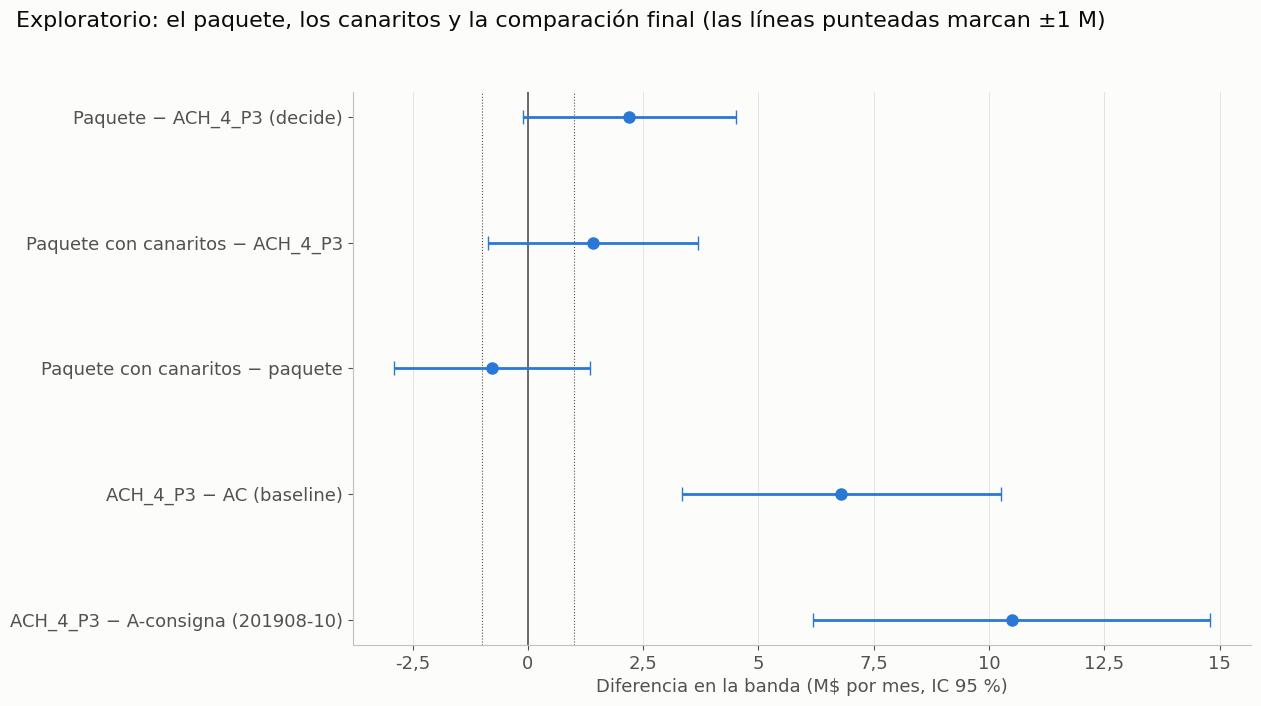

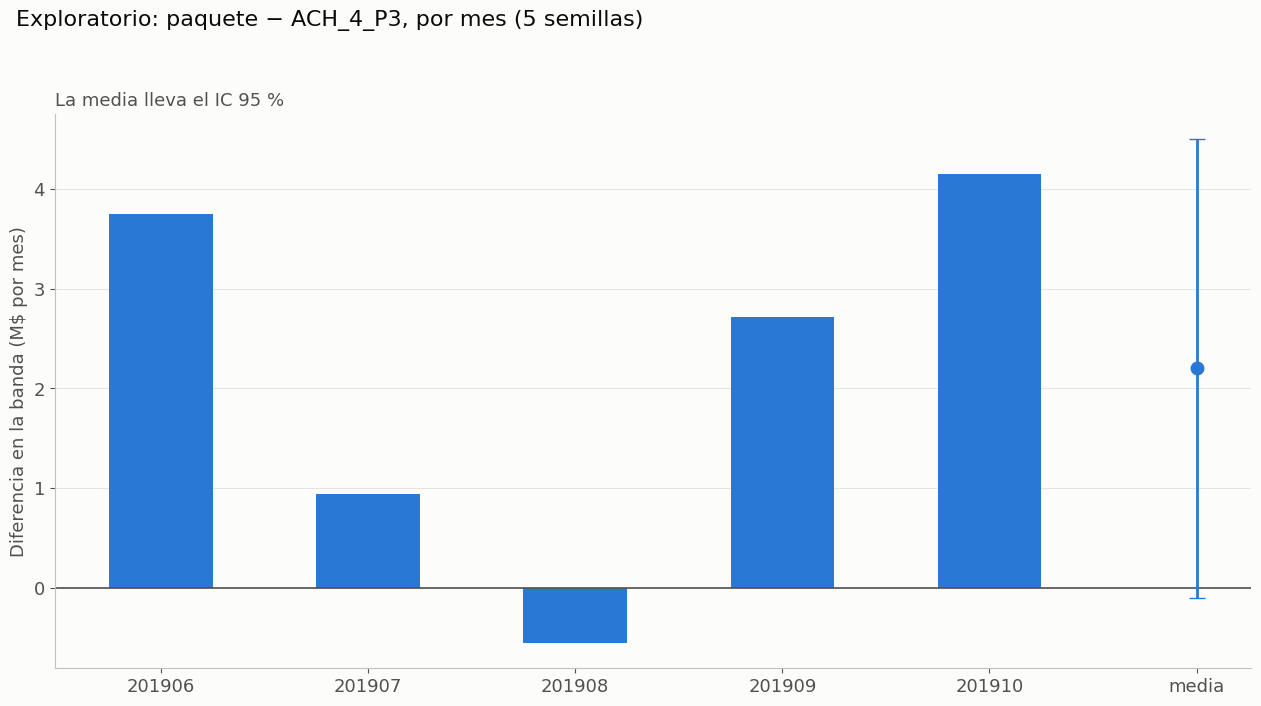

In [11]:
TINTA_2, GRILLA, AZUL = '#52514e', '#e1e0d9', '#2a78d6'
plt.rcParams.update({'figure.facecolor': '#fcfcfb', 'axes.facecolor': '#fcfcfb', 'axes.edgecolor': '#c3c2b7',
                     'axes.labelcolor': TINTA_2, 'xtick.color': TINTA_2, 'ytick.color': TINTA_2, 'text.color': '#0b0b0b',
                     'axes.grid': True, 'grid.color': GRILLA, 'grid.linewidth': 0.6, 'axes.spines.top': False,
                     'axes.spines.right': False, 'font.size': 13, 'axes.titlesize': 15})
TAMANO, DPI = (12.8, 7.2), 150


def coma(x, decimales=1):
    return f'{x:,.{decimales}f}'.replace(',', '_').replace('.', ',').replace('_', '.')


formato = FuncFormatter(lambda v, _: coma(v, 2).rstrip('0').rstrip(','))
NOMBRES = {(PAQUETE, REFERENCIA): 'Paquete − ACH_4_P3 (decide)', (CON_CANARITOS, REFERENCIA): 'Paquete con canaritos − ACH_4_P3',
           (CON_CANARITOS, PAQUETE): 'Paquete con canaritos − paquete', (REFERENCIA, 'AC'): 'ACH_4_P3 − AC (baseline)',
           (REFERENCIA, CONSIGNA): 'ACH_4_P3 − A-consigna (201908-10)'}

fig, ax = plt.subplots(figsize=TAMANO)
r = comparacion.iloc[::-1].reset_index(drop=True)
y = np.arange(len(r))
ax.axvline(0, color=TINTA_2, lw=1.2)
for lado in (-UMBRAL, UMBRAL):
    ax.axvline(lado, color=TINTA_2, lw=0.8, ls=':')
ax.errorbar(r['d_M'], y, xerr=[r['d_M'] - r['ic95_inf_M'], r['ic95_sup_M'] - r['d_M']], fmt='o', color=AZUL, ms=8, capsize=5, lw=2)
ax.set_yticks(y, [NOMBRES[(a, b)] for a, b in zip(r['config'], r['contra'])])
ax.xaxis.set_major_formatter(formato)
ax.set_xlabel('Diferencia en la banda (M$ por mes, IC 95 %)')
ax.grid(axis='y', visible=False)
fig.suptitle('Exploratorio: el paquete, los canaritos y la comparación final (las líneas punteadas marcan ±1 M)', x=0.02, ha='left', fontsize=16)
fig.tight_layout(rect=(0, 0, 1, 0.95))
fig.savefig(FIGURAS / '22_1_canaritos.png', dpi=DPI)
plt.show()

r = comparacion.iloc[0]
fig, ax = plt.subplots(figsize=TAMANO)
ax.axhline(0, color=TINTA_2, lw=1.2)
x = [str(m) for m in MESES_EVALUADOS] + ['media']
ax.bar(x[:-1], [r[f'd_{m}'] for m in MESES_EVALUADOS], color=AZUL, width=0.5)
ax.errorbar([x[-1]], [r.d_M], yerr=[[r.d_M - r.ic95_inf_M], [r.ic95_sup_M - r.d_M]], fmt='o', color=AZUL, ms=9, capsize=6, lw=2)
ax.yaxis.set_major_formatter(formato)
ax.set_ylabel('Diferencia en la banda (M$ por mes)')
ax.grid(axis='x', visible=False)
ax.set_axisbelow(True)
fig.suptitle('Exploratorio: paquete − ACH_4_P3, por mes (5 semillas)', x=0.02, ha='left', fontsize=16)
ax.set_title('La media lleva el IC 95 %', loc='left', color=TINTA_2, fontsize=13)
fig.tight_layout(rect=(0, 0, 1, 0.95))
fig.savefig(FIGURAS / '22_2_por_mes.png', dpi=DPI)
plt.show()

## 12. Lectura fijada antes de correr

Decide `PAQ_P3` contra `ACH_4_P3`, con `d` = la diferencia media en la banda:

| `d` | Lectura |
|---|---|
| +1 M o más | Suma: el paquete pasa a ser la vigente |
| Entre −1 y +1 M | Empate: queda `ACH_4_P3`, que es más simple |
| −1 M o menos | Resta: queda `ACH_4_P3` |

El paquete con canaritos y la comparación final informan, no deciden. El intervalo se informa siempre.

**Control 9:** las salidas anteriores no cambiaron.

In [12]:
assert huella_archivos() == HUELLA_INICIAL, 'Cambiaron las salidas anteriores'   # control 9
print(f'Control de salidas OK · {(time.time() - T_INICIO) / 60:.1f} min en total · memoria máxima {memoria_gb()} GB')
if segundos:
    print('Segundos por modelo:', {c: round(float(np.mean(v)), 1) for c, v in segundos.items()})
print('Segundos por selección:', {m: SELECCION[m]['segundos'] for m in MESES_EVALUADOS})
print()
print('EXPLORATORIO: no cambia el resultado de la regla pre-registrada.')
print()

lectura = lambda d: 'Suma' if d >= UMBRAL else ('Resta' if d <= -UMBRAL else 'Empate')
for r in comparacion.itertuples():
    marca = ' · DECIDE' if (r.config, r.contra) == (DECIDE, REFERENCIA) else ''
    print(f'{NOMBRES[(r.config, r.contra)]}: {r.d_M:+.2f} M ({r.ic95_inf_M:.2f} a {r.ic95_sup_M:.2f}) · error {r.error_total_M:.2f} M · '
          f'ensamble {r.d_ensamble_M:+.2f} M · semillas a favor {r.semillas_a_favor} de {N_SEMILLAS} · {lectura(r.d_M)}{marca}')

t = comparacion.set_index(['config', 'contra'])
pd.DataFrame([{'config': c, 'hipotesis': HIPOTESIS[c], 'contra': REFERENCIA,
               'columnas': len(COLUMNAS_PAQUETE) if c == PAQUETE else round(float(np.mean([len(SELECCION[m]['elegidas']) for m in MESES_EVALUADOS]))),
               'd_M': round(t.loc[(c, REFERENCIA), 'd_M'], 3), 'resultado': lectura(t.loc[(c, REFERENCIA), 'd_M']),
               'decide': c == DECIDE} for c in CONFIGS]).to_csv(RESULTADOS / '22_iteraciones.tsv', sep='\t', index=False)

Control de salidas OK · 56.3 min en total · memoria máxima 6.9 GB
Segundos por modelo: {'PAQ_P3': 66.4, 'PAQ_C_P3': 21.3, 'A_CONSIGNA': 35.0}
Segundos por selección: {201906: 69.6, 201907: 120.7, 201908: 153.8, 201909: 195.0, 201910: 217.7}

EXPLORATORIO: no cambia el resultado de la regla pre-registrada.

Paquete − ACH_4_P3 (decide): +2.20 M (-0.10 a 4.50) · error 1.17 M · ensamble +2.45 M · semillas a favor 5 de 5 · Suma · DECIDE
Paquete con canaritos − ACH_4_P3: +1.41 M (-0.86 a 3.69) · error 1.16 M · ensamble +1.35 M · semillas a favor 4 de 5 · Suma
Paquete con canaritos − paquete: -0.79 M (-2.92 a 1.34) · error 1.09 M · ensamble -1.10 M · semillas a favor 1 de 5 · Empate
ACH_4_P3 − AC (baseline): +6.80 M (3.34 a 10.26) · error 1.76 M · ensamble +6.76 M · semillas a favor 5 de 5 · Suma
ACH_4_P3 − A-consigna (201908-10): +10.49 M (6.19 a 14.80) · error 2.20 M · ensamble +10.15 M · semillas a favor 5 de 5 · Suma
